In [ ]:
!pip -q install fastapi uvicorn gradio pyngrok requests pillow pandas matplotlib scikit-learn

In [ ]:
import os, random, json, time, subprocess, textwrap, pathlib, sys
import numpy as np
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Python:", sys.version)
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
TensorFlow: 2.21.0
NumPy: 2.4.6
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

x_train = (x_train.astype("float32") / 255.0)[..., None]
x_test = (x_test.astype("float32") / 255.0)[..., None]

print("Train:", x_train.shape, y_train.shape)
print("Test:", x_test.shape, y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train: (60000, 28, 28, 1) (60000,)
Test: (10000, 28, 28, 1) (10000,)


In [ ]:
def build_model():
    inputs = tf.keras.Input(shape=(28, 28, 1), name="image")
    x = tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)
    x = tf.keras.layers.MaxPooling2D()(x)
    x = tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = tf.keras.layers.MaxPooling2D()(x)
    x = tf.keras.layers.Flatten()(x)
    x = tf.keras.layers.Dense(128, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.25)(x)
    outputs = tf.keras.layers.Dense(10, activation="softmax", name="probabilities")(x)
    return tf.keras.Model(inputs, outputs)

model = build_model()
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probabilities (Dense)           │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy", patience=2, restore_best_weights=True
    )
]
history = model.fit(
    x_train, y_train,
    validation_split=0.1,
    epochs=8,
    batch_size=128,
    callbacks=callbacks,
    verbose=1
)

test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Original model test accuracy: {test_acc:.4f}")

Epoch 1/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 28s 30ms/step - accuracy: 0.9304 - loss: 0.2292 - val_accuracy: 0.9852 - val_loss: 0.0526
Epoch 2/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 19s 7ms/step - accuracy: 0.9802 - loss: 0.0639 - val_accuracy: 0.9873 - val_loss: 0.0426
Epoch 3/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9857 - loss: 0.0453 - val_accuracy: 0.9887 - val_loss: 0.0397
Epoch 4/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9890 - loss: 0.0356 - val_accuracy: 0.9913 - val_loss: 0.0342
Epoch 5/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9908 - loss: 0.0288 - val_accuracy: 0.9910 - val_loss: 0.0337
Epoch 6/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9928 - loss: 0.0230 - val_accuracy: 0.9923 - val_loss: 0.0307
Epoch 7/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9935 - loss: 0.0201 - val_accuracy: 0.9903 - val_loss: 0.0379
Epoch 8/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9946 - loss: 0.0167 - val_accuracy: 0.9890 

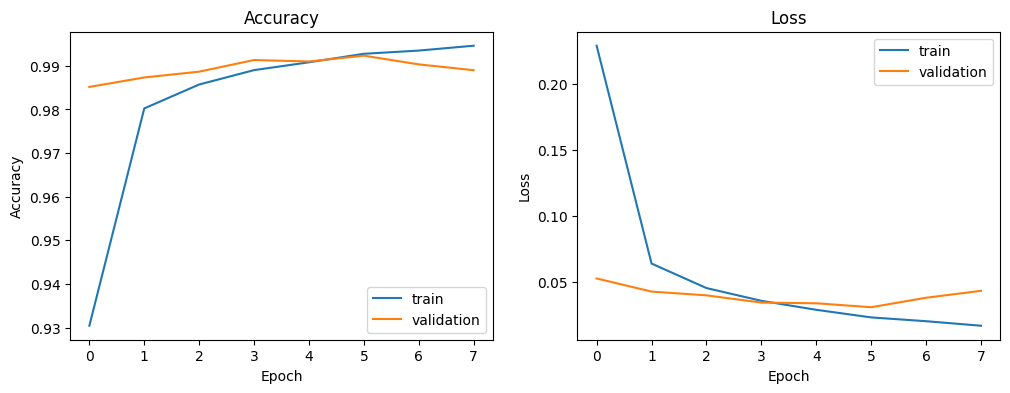

In [ ]:
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.title("Accuracy")
plt.subplot(1,2,2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.title("Loss")
plt.show()

In [ ]:
WORK_DIR = "/content/deployment_project"
os.makedirs(WORK_DIR, exist_ok=True)

KERAS_PATH = f"{WORK_DIR}/mnist_cnn.keras"
model.save(KERAS_PATH)

def convert_float32(keras_model):
    converter = tf.lite.TFLiteConverter.from_keras_model(keras_model)
    return converter.convert()

tflite_float = convert_float32(model)
FLOAT_PATH = f"{WORK_DIR}/model_float32.tflite"
open(FLOAT_PATH, "wb").write(tflite_float)

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_dynamic = converter.convert()
DYNAMIC_PATH = f"{WORK_DIR}/model_dynamic_quant.tflite"
open(DYNAMIC_PATH, "wb").write(tflite_dynamic)

def representative_data():
    for i in range(300):
        yield [x_train[i:i+1].astype(np.float32)]

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_data
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8
tflite_int8 = converter.convert()
INT8_PATH = f"{WORK_DIR}/model_int8.tflite"
open(INT8_PATH, "wb").write(tflite_int8)

print("TFLite fayllari yaratildi.")

Saved artifact at '/tmp/tmpn0mrustu'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  133447901996880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133447901997840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133447901997456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133447901998224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133447901998032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133447901997648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133447901997072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133447901999376: TensorSpec(shape=(), dtype=tf.resource, name=None)
Saved artifact at '/tmp/tmpn7re5psl'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28, 1), dty

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


TFLite fayllari yaratildi.


In [ ]:
import copy

pruned_model = tf.keras.models.clone_model(model)
pruned_model.set_weights(model.get_weights())

for layer in pruned_model.layers:
    if isinstance(layer, (tf.keras.layers.Conv2D, tf.keras.layers.Dense)):
        weights = layer.get_weights()
        if weights:
            kernel = weights[0]
            threshold = np.percentile(np.abs(kernel), 50)
            kernel[np.abs(kernel) < threshold] = 0.0
            weights[0] = kernel
            layer.set_weights(weights)

pruned_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
pruned_loss, pruned_acc = pruned_model.evaluate(x_test, y_test, verbose=0)
print(f"Pruned model test accuracy: {pruned_acc:.4f}")

converter = tf.lite.TFLiteConverter.from_keras_model(pruned_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_pruned = converter.convert()
PRUNED_PATH = f"{WORK_DIR}/model_pruned.tflite"
open(PRUNED_PATH, "wb").write(tflite_pruned)

Pruned model test accuracy: 0.9857
Saved artifact at '/tmp/tmpc6o7jn8a'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  133447521903120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133447521904080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133447521903888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133447521904464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133447521904272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133447521904848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133447521905616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133447521906576: TensorSpec(shape=(), dtype=tf.resource, name=None)


430152

In [ ]:
def tflite_predict(path, images):
    interpreter = tf.lite.Interpreter(model_path=path)
    interpreter.allocate_tensors()
    input_info = interpreter.get_input_details()[0]
    output_info = interpreter.get_output_details()[0]
    preds = []

    for image in images:
        batch = image[None, ...].astype(np.float32)
        if input_info["dtype"] == np.int8:
            scale, zero = input_info["quantization"]
            batch = np.round(batch / scale + zero).astype(np.int8)
        interpreter.set_tensor(input_info["index"], batch)
        interpreter.invoke()
        out = interpreter.get_tensor(output_info["index"])
        if output_info["dtype"] == np.int8:
            scale, zero = output_info["quantization"]
            out = (out.astype(np.float32) - zero) * scale
        preds.append(out[0])
    return np.array(preds)

def evaluate_tflite(path, images=x_test[:2000], labels=y_test[:2000]):
    start = time.perf_counter()
    probs = tflite_predict(path, images)
    elapsed = time.perf_counter() - start
    acc = np.mean(np.argmax(probs, axis=1) == labels)
    size_mb = os.path.getsize(path) / (1024**2)
    return acc, size_mb, elapsed / len(images) * 1000

rows = []
for label, path in [
    ("Keras original", KERAS_PATH),
    ("TFLite float32", FLOAT_PATH),
    ("TFLite dynamic quant", DYNAMIC_PATH),
    ("TFLite full int8", INT8_PATH),
    ("TFLite pruned + optimize", PRUNED_PATH),
]:
    if label == "Keras original":
        start = time.perf_counter()
        probs = model.predict(x_test[:2000], verbose=0)
        elapsed = time.perf_counter() - start
        acc = np.mean(np.argmax(probs, axis=1) == y_test[:2000])
        size_mb = os.path.getsize(path) / (1024**2)
        ms = elapsed / 2000 * 1000
    else:
        acc, size_mb, ms = evaluate_tflite(path)
    rows.append({
        "Variant": label,
        "Accuracy": acc,
        "Size_MB": size_mb,
        "Avg_inference_ms_per_image": ms
    })

results_df = pd.DataFrame(rows)
display(results_df.round(4))
results_df.to_csv(f"{WORK_DIR}/optimization_results.csv", index=False)

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


,Variant,Accuracy,Size_MB,Avg_inference_ms_per_image
0,Keras original,0.9850,4.8666,0.4498
1,TFLite float32,0.9850,1.6126,0.2670
2,TFLite dynamic quant,0.9850,0.4102,0.3218
3,TFLite full int8,0.9845,0.4128,0.5256
4,TFLite pruned + optimize,0.9805,0.4102,0.3466


In [ ]:
API_CODE = r'''
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel
import numpy as np
import tensorflow as tf

app = FastAPI(title="MNIST Digit Classifier API", version="1.0.0")
MODEL_PATH = "model_int8.tflite"

interpreter = tf.lite.Interpreter(model_path=MODEL_PATH)
interpreter.allocate_tensors()
inp = interpreter.get_input_details()[0]
out = interpreter.get_output_details()[0]

class PredictRequest(BaseModel):
    image: list

@app.get("/")
def root():
    return {"message": "MNIST API is running"}

@app.get("/health")
def health():
    return {"status": "ok"}

@app.post("/predict")
def predict(request: PredictRequest):
    arr = np.asarray(request.image, dtype=np.float32)
    if arr.shape != (28, 28):
        raise HTTPException(status_code=400, detail="image shape must be 28x28")
    arr = (arr / 255.0)[None, ..., None]

    if inp["dtype"] == np.int8:
        scale, zero = inp["quantization"]
        arr = np.round(arr / scale + zero).astype(np.int8)
    interpreter.set_tensor(inp["index"], arr)
    interpreter.invoke()
    pred = interpreter.get_tensor(out["index"])
    if out["dtype"] == np.int8:
        scale, zero = out["quantization"]
        pred = (pred.astype(np.float32) - zero) * scale

    probabilities = pred[0].astype(float).tolist()
    return {
        "predicted_class": int(np.argmax(probabilities)),
        "probabilities": probabilities
    }
'''
open(f"{WORK_DIR}/app.py", "w").write(API_CODE)
print(API_CODE)


from fastapi import FastAPI, HTTPException
from pydantic import BaseModel
import numpy as np
import tensorflow as tf

app = FastAPI(title="MNIST Digit Classifier API", version="1.0.0")
MODEL_PATH = "model_int8.tflite"

interpreter = tf.lite.Interpreter(model_path=MODEL_PATH)
interpreter.allocate_tensors()
inp = interpreter.get_input_details()[0]
out = interpreter.get_output_details()[0]

class PredictRequest(BaseModel):
    image: list

@app.get("/")
def root():
    return {"message": "MNIST API is running"}

@app.get("/health")
def health():
    return {"status": "ok"}

@app.post("/predict")
def predict(request: PredictRequest):
    arr = np.asarray(request.image, dtype=np.float32)
    if arr.shape != (28, 28):
        raise HTTPException(status_code=400, detail="image shape must be 28x28")
    arr = (arr / 255.0)[None, ..., None]

    if inp["dtype"] == np.int8:
        scale, zero = inp["quantization"]
        arr = np.round(arr / scale + zero).astype(np.int8)
    interpreter.set_t

In [ ]:

import subprocess
import sys
import time
import requests

# Eski server jarayonini to'xtatish
try:
    server_process.terminate()
    server_process.wait(timeout=5)
except:
    pass

# Yangi server
server_log = open(f"{WORK_DIR}/uvicorn.log", "w")

server_process = subprocess.Popen(
    [
        sys.executable, "-m", "uvicorn",
        "app:app",
        "--host", "127.0.0.1",
        "--port", "8000"
    ],
    cwd=WORK_DIR,
    stdout=server_log,
    stderr=subprocess.STDOUT
)

# Server tayyor bo'lishini kutish
for i in range(15):
    time.sleep(2)
    try:
        r = requests.get(
            "http://127.0.0.1:8000/health",
            timeout=3
        )
        print("Server ishlayapti!")
        print(r.json())
        break
    except requests.exceptions.RequestException:
        print(f"Kutilyapti... {i+1}/15")
else:
    print("Server ishga tushmadi. Logni tekshiring:")
    print(open(f"{WORK_DIR}/uvicorn.log").read())


Kutilyapti... 1/15
Kutilyapti... 2/15
Server ishlayapti!
{'status': 'ok'}


In [ ]:
sample_image = (x_test[0, :, :, 0] * 255).astype(np.uint8)
payload = {"image": sample_image.tolist()}
response = requests.post("http://127.0.0.1:8000/predict", json=payload)
print("HTTP status:", response.status_code)
print("API result:", response.json())
print("True label:", int(y_test[0]))

HTTP status: 200
API result: {'predicted_class': 7, 'probabilities': [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.99609375, 0.0, 0.0]}
True label: 7


In [ ]:
# Bu katakni faqat tashqi URL kerak bo‘lsa ishga tushiring.
from getpass import getpass
from pyngrok import ngrok

NGROK_TOKEN = getpass("Ngrok authtoken (kiritish ixtiyoriy, bo‘sh qoldirish mumkin): ")
if NGROK_TOKEN.strip():
    ngrok.set_auth_token(NGROK_TOKEN.strip())
    public_url = ngrok.connect(8000, "http").public_url
    print("Public API URL:", public_url)
else:
    public_url = None
    print("Ngrok o'tkazib yuborildi. Local API: http://127.0.0.1:8000")

In [18]:
import gradio as gr
from PIL import Image

API_URL = "http://127.0.0.1:8000/predict"

def classify_digit(image):
    if image is None:
        return {"Xatolik": 1.0}
    img = Image.fromarray(image).convert("L").resize((28, 28))
    arr = np.asarray(img, dtype=np.uint8)
    result = requests.post(API_URL, json={"image": arr.tolist()}, timeout=30)
    result.raise_for_status()
    data = result.json()
    return {str(i): float(p) for i, p in enumerate(data["probabilities"])}

demo = gr.Interface(
    fn=classify_digit,
    inputs=gr.Image(type="numpy", image_mode="RGB", label="Raqam rasmini yuklang"),
    outputs=gr.Label(num_top_classes=5, label="Model bashorati"),
    title="MNIST raqamlarini aniqlash",
    description="Rasm 28×28 grayscale ko‘rinishga keltirilib, FastAPI + TFLite orqali tasniflanadi."
)

In [19]:
# Demo ishga tushirish. share=True tashqi vaqtinchalik URL beradi.
demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2ced3f7345ea81c435.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [20]:
DOCKERFILE = '''
FROM python:3.11-slim
WORKDIR /app
RUN pip install --no-cache-dir fastapi uvicorn pydantic numpy tensorflow-cpu
COPY app.py .
COPY model_int8.tflite .
EXPOSE 8000
CMD ["uvicorn", "app:app", "--host", "0.0.0.0", "--port", "8000"]
'''
open(f"{WORK_DIR}/Dockerfile", "w").write(textwrap.dedent(DOCKERFILE).strip() + "\n")
print(open(f"{WORK_DIR}/Dockerfile").read())

FROM python:3.11-slim
WORKDIR /app
RUN pip install --no-cache-dir fastapi uvicorn pydantic numpy tensorflow-cpu
COPY app.py .
COPY model_int8.tflite .
EXPOSE 8000
CMD ["uvicorn", "app:app", "--host", "0.0.0.0", "--port", "8000"]



In [21]:
TEST_CODE = '''
import numpy as np
from fastapi.testclient import TestClient
from app import app

client = TestClient(app)

def test_health():
    response = client.get("/health")
    assert response.status_code == 200
    assert response.json()["status"] == "ok"

def test_predict():
    image = np.zeros((28, 28), dtype=int).tolist()
    response = client.post("/predict", json={"image": image})
    assert response.status_code == 200
    data = response.json()
    assert 0 <= data["predicted_class"] <= 9
    assert len(data["probabilities"]) == 10
'''
os.makedirs(f"{WORK_DIR}/tests", exist_ok=True)
open(f"{WORK_DIR}/tests/test_api.py", "w").write(textwrap.dedent(TEST_CODE).strip() + "\n")

CI_YML = '''
name: CI - Test and Build Docker
on:
  push:
    branches: [ "main" ]
  pull_request:
    branches: [ "main" ]

jobs:
  test-and-build:
    runs-on: ubuntu-latest
    steps:
      - name: Checkout
        uses: actions/checkout@v4
      - name: Set up Python
        uses: actions/setup-python@v5
        with:
          python-version: "3.11"
      - name: Install dependencies
        run: |
          python -m pip install --upgrade pip
          pip install fastapi uvicorn pydantic numpy tensorflow-cpu pytest httpx
      - name: Run tests
        run: pytest -q
      - name: Build Docker image
        run: docker build -t mnist-deployment:latest .
'''
os.makedirs(f"{WORK_DIR}/.github/workflows", exist_ok=True)
open(f"{WORK_DIR}/.github/workflows/ci.yml", "w").write(textwrap.dedent(CI_YML).strip() + "\n")
print("CI workflow va test fayli yaratildi.")

CI workflow va test fayli yaratildi.


In [22]:
DRIFT_CODE = r'''
import numpy as np
import json

def summarize(x):
    x = np.asarray(x, dtype=np.float32)
    return {
        "mean": float(x.mean()),
        "std": float(x.std())
    }

def compare(reference, production):
    ref = summarize(reference)
    prod = summarize(production)
    mean_shift = abs(prod["mean"] - ref["mean"])
    std_shift = abs(prod["std"] - ref["std"])
    return {
        "reference": ref,
        "production": prod,
        "mean_shift": mean_shift,
        "std_shift": std_shift,
        "possible_drift": bool(mean_shift > 0.05 or std_shift > 0.05)
    }

if __name__ == "__main__":
    # Demo uchun MNIST test rasmlaridan foydalaniladi.
    from tensorflow.keras.datasets import mnist
    (x_train, _), (x_test, _) = mnist.load_data()
    reference = x_train[:1000] / 255.0
    production = x_test[:1000] / 255.0
    print(json.dumps(compare(reference, production), indent=2))
'''
open(f"{WORK_DIR}/drift_monitor.py", "w").write(textwrap.dedent(DRIFT_CODE).strip() + "\n")
print("drift_monitor.py yaratildi.")

drift_monitor.py yaratildi.


In [23]:
MODEL_CARD = f'''
# Model Card: MNIST CNN Digit Classifier

## Model details
- Model: CNN (Conv2D, MaxPooling, Dense)
- Task: handwritten digit classification (10 classes)
- Input: 28x28 grayscale image
- Output: 10 class probabilities
- Deployment: TensorFlow Lite int8 + FastAPI + Gradio

## Intended use
Educational demonstration and experimentation on MNIST-like handwritten digits.

## Training data
MNIST training split. Images normalized to [0, 1].

## Evaluation
- Test accuracy (Keras): {test_acc:.4f}
- TFLite int8 accuracy: {evaluate_tflite(INT8_PATH)[0]:.4f}

## Limitations
- Performance may degrade on colored, rotated, noisy, or non-MNIST handwriting.
- The model is not intended for identity, financial, medical, or other high-stakes decisions.
- The demo API accepts only 28x28 grayscale image arrays.

## Ethical considerations
- MNIST is a narrow benchmark and does not represent all writing styles or populations.
- Do not use this model as the sole basis for consequential decisions.
- Uploaded images should be handled with appropriate privacy and security safeguards.

## Monitoring
The included drift_monitor.py compares basic input mean and standard deviation.
'''
open(f"{WORK_DIR}/MODEL_CARD.md", "w").write(MODEL_CARD)
print(MODEL_CARD)

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)



# Model Card: MNIST CNN Digit Classifier

## Model details
- Model: CNN (Conv2D, MaxPooling, Dense)
- Task: handwritten digit classification (10 classes)
- Input: 28x28 grayscale image
- Output: 10 class probabilities
- Deployment: TensorFlow Lite int8 + FastAPI + Gradio

## Intended use
Educational demonstration and experimentation on MNIST-like handwritten digits.

## Training data
MNIST training split. Images normalized to [0, 1].

## Evaluation
- Test accuracy (Keras): 0.9904
- TFLite int8 accuracy: 0.9845

## Limitations
- Performance may degrade on colored, rotated, noisy, or non-MNIST handwriting.
- The model is not intended for identity, financial, medical, or other high-stakes decisions.
- The demo API accepts only 28x28 grayscale image arrays.

## Ethical considerations
- MNIST is a narrow benchmark and does not represent all writing styles or populations.
- Do not use this model as the sole basis for consequential decisions.
- Uploaded images should be handled with appropri

In [24]:
import zipfile

zip_path = "/content/Deep_Learning_Task_10_Deployment.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, files in os.walk(WORK_DIR):
        for filename in files:
            full = os.path.join(root, filename)
            arc = os.path.relpath(full, WORK_DIR)
            z.write(full, arc)

print("Project folder:", WORK_DIR)
print("ZIP:", zip_path)
print("Generated files:")
for root, dirs, files in os.walk(WORK_DIR):
    for filename in files:
        print(os.path.relpath(os.path.join(root, filename), WORK_DIR))

Project folder: /content/deployment_project
ZIP: /content/Deep_Learning_Task_10_Deployment.zip
Generated files:
model_int8.tflite
model_float32.tflite
MODEL_CARD.md
Dockerfile
model_pruned.tflite
model_dynamic_quant.tflite
uvicorn.log
optimization_results.csv
drift_monitor.py
app.py
mnist_cnn.keras
__pycache__/app.cpython-313.pyc
tests/test_api.py
.github/workflows/ci.yml


In [25]:

# FastAPI nima sababdan ishga tushmaganini tekshiramiz

print("Server process:", server_process.poll())

log_path = f"{WORK_DIR}/uvicorn.log"

if os.path.exists(log_path):
    with open(log_path, "r") as f:
        print(f.read())
else:
    print("Log fayli topilmadi!")


Server process: 0
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
INFO:     Started server process [2842]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://127.0.0.1:8000 (Press CTRL+C to quit)
INFO:     127.0.0.1:49656 - "GET /health HTTP/1.1" 200 OK
INFO:     127.0.0.1:51414 - "POST /predict HTTP/1.1" 200 OK
INFO:     Shutting down
INFO:     Waiting for application shutdown.
INFO:     Application shutdown complete.
INFO:     Finished server process [2842]

